# Laboratorio 11: Redes neuronales convolucionales

**Mateo Caballero** - Aprendizaje Estadístico - semestre 2026-2

Enunciado original: `semestre2026-2/Laboratorios/Laboratorio_11_redes_neuronales_convolucionales.ipynb`
(material de apoyo: `semestre2026-2/Sesiones/Sesion_17_convolution_nn2.ipynb`)

Cada bloque empieza con el enunciado original, copiado sin cambios, y debajo va el desarrollo de cada
punto. El laboratorio tiene tres partes:

1. LeNet-5 en MNIST (puntos 1-12).
2. La arquitectura del punto 12 en CIFAR-100, con BatchNormalization y Dropout (puntos 13-15).
3. Clasificación de imágenes con una VGG16 preentrenada en ImageNet.

**Entorno.** Python 3.14, TensorFlow 2.22.0rc0 (la única versión publicada para Python 3.14) y
Keras 3.15.1, en CPU. El código es el mismo que correría en Colab.

**Cambios al código del enunciado**, todos mínimos y comentados en su celda: `keras.Input(shape=...)` en
lugar de `input_shape=...` (Keras 3 desaconseja lo segundo); `urllib` en lugar de `!wget`, que solo
funciona en Colab; el modelo del punto 12 se llama `model_alt` para no sobrescribir el LeNet-5 del punto 5;
y `verbose=2` en los `fit`, que imprime una línea por época. Además se silencia un aviso de TensorFlow por
`keras.backend.clear_session()`, porque repetiría la ruta local de este equipo.

> **Enunciado**
>
> # Laboratorio redes neuronales convolucionales
> 
> Objetivo: Implementar un red neuronal LeNet5 empleando keras e implementar una red neuronal  VGG.

## Parte 1. LeNet-5 en MNIST

> **Enunciado**
>
> 1. Importar las librerias:
> ```python
> import numpy as np
> import pandas as pd
> import matplotlib.pyplot as plt
> import seaborn as sns
> sns.set()
> from tensorflow import keras
> ```

### Punto 1. Librerías

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"     # oculta los registros internos de C++ de TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import confusion_matrix

SEED = 42
tf.config.experimental.enable_op_determinism()   # misma semilla -> mismos números
# keras.backend.clear_session() (que sugiere el enunciado) provoca un aviso de TensorFlow por una función
# obsoleta; se silencia solo ese, porque repetiría la ruta local en la salida
tf.get_logger().addFilter(lambda registro: "reset_default_graph" not in registro.getMessage())
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU disponibles:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.22.0-rc0 | Keras 3.15.1


GPU disponibles: []


> **Enunciado**
>
> 2. Cargar los datos de entrenamiento y test
> ```python
> (X_train,y_train),(X_test,y_test)=keras.datasets.mnist.load_data()
> ```

### Punto 2. Datos de entrenamiento y test

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
print("X_train:", X_train.shape, X_train.dtype, "| X_test:", X_test.shape)
print("Ejemplos por dígito en train:", np.bincount(y_train))
print("Ejemplos por dígito en test: ", np.bincount(y_test))

X_train: (60000, 28, 28) uint8 | X_test: (10000, 28, 28)
Ejemplos por dígito en train: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
Ejemplos por dígito en test:  [ 980 1135 1032 1010  982  892  958 1028  974 1009]


> **Enunciado**
>
> 3. Normalizar los datos.

### Punto 3. Normalización

In [3]:
X_train = X_train / 255.0
X_test = X_test / 255.0
print("Rango después de normalizar:", X_train.min(), "a", X_train.max())

Rango después de normalizar: 0.0 a 1.0


> **Enunciado**
>
> 4. Realizar una visualización de 20 imagenes aproximadamente, puede emplear el comando imshow con cmap= binary
> 
> ```python
>   ax.imshow(X_train[i],cmap='binary')
> ```

### Punto 4. Visualización

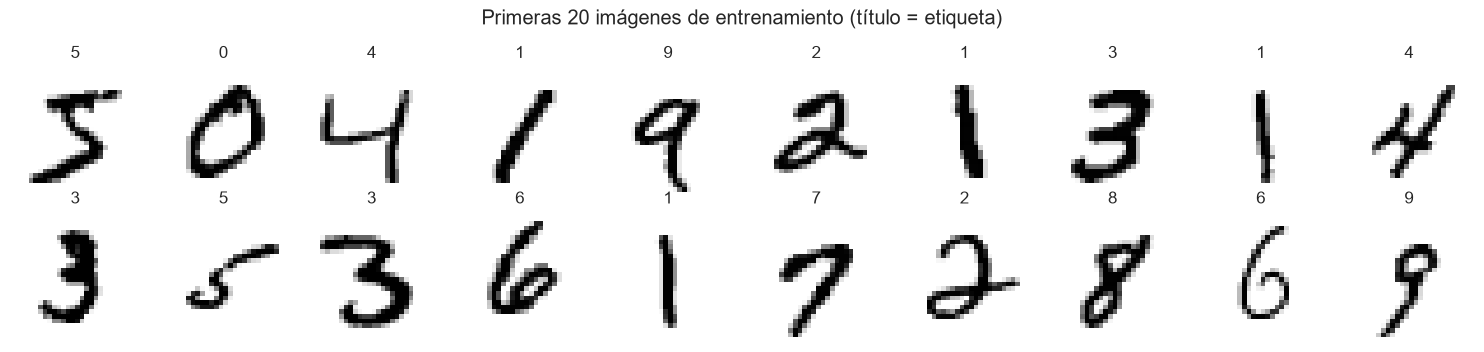

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(15, 3.6))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap="binary")
    ax.set_title(y_train[i])
    ax.axis("off")
plt.suptitle("Primeras 20 imágenes de entrenamiento (título = etiqueta)")
plt.tight_layout(); plt.show()

> **Enunciado**
>
> 5. Implementar en keras, la red Letnet5, la arquitectura de la red es la siguiente:
> 
> ![img](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/LeNet5.png?raw=true)
> 
> 
> Par la implementación, se recomienda construir un modelo secuencial.
> 
> 
> ```python
> keras.backend.clear_session()
> models=keras.models.Sequential([...])
> 
> ```
> 
> algunos parámetros que pueden ser pasados dentro de los tres puntos anteriores son:
> 
> 
> ```python
> keras.layers.MaxPool2D,
> keras.layers.Conv2D,
> keras.layers.Flatten,
> keras.layers.Dense
> ```
> 
> Revisa la documentación para pasar los valores adecuados.

### Punto 5. Implementación de LeNet-5

La red sigue la figura del enunciado capa por capa:

| Capa | Operación | Salida |
|---|---|---|
| Entrada | imagen | $32\times32\times1$ |
| C1 | 6 filtros $5\times5$, paso 1 | $28\times28\times6$ |
| S2 | *average pooling* $2\times2$, paso 2 | $14\times14\times6$ |
| C3 | 16 filtros $5\times5$, paso 1 | $10\times10\times16$ |
| S4 | *average pooling* $2\times2$, paso 2 | $5\times5\times16 = 400$ |
| F5, F6 | densas | 120, 84 |
| Salida | softmax | 10 |

Decisiones:

- **Entrada de 32×32.** Las imágenes de MNIST son de $28\times28$. Se rellenan con 2 píxeles de ceros
  por lado (`ZeroPadding2D(2)`) para obtener la entrada de $32\times32$ de la figura. Así todas las
  dimensiones intermedias coinciden con las de la figura.
- **Pooling promedio.** La figura indica *avg pool*, por eso se usa `AveragePooling2D`, aunque la lista
  de capas sugeridas del enunciado menciona `MaxPool2D`. El modelo del punto 12 usa *max pooling*, así
  que la comparación entre ambos también muestra ese cambio.
- **Activación.** La figura no indica la activación de las capas ocultas. Se usa relu, la misma del
  punto 12 y del resto del curso.

In [5]:
# Keras espera un canal explícito: (n, 28, 28) -> (n, 28, 28, 1)
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model = keras.models.Sequential([
    keras.Input(shape=(28, 28, 1)),
    keras.layers.ZeroPadding2D(padding=2),                                   # 28x28 -> 32x32, como en la figura
    keras.layers.Conv2D(6, kernel_size=5, strides=1, activation="relu"),    # 32x32x1 -> 28x28x6
    keras.layers.AveragePooling2D(pool_size=2, strides=2),                  # -> 14x14x6
    keras.layers.Conv2D(16, kernel_size=5, strides=1, activation="relu"),   # -> 10x10x16
    keras.layers.AveragePooling2D(pool_size=2, strides=2),                  # -> 5x5x16
    keras.layers.Flatten(),                                                 # -> 400
    keras.layers.Dense(120, activation="relu"),
    keras.layers.Dense(84, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
], name="LeNet5")

> **Enunciado**
>
> 6. Revisa el modelo que acabaste de construir.
> ```python
> model.summary()
> ```

### Punto 6. Revisión del modelo

In [6]:
model.summary()

Model: "LeNet5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ zero_padding2d (ZeroPadding2D)  │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Parámetros a mano: Conv2D = (k*k*canales_entrada + 1) * filtros;  Dense = (entradas + 1) * neuronas
a_mano = {"conv 1": (5 * 5 * 1 + 1) * 6, "conv 2": (5 * 5 * 6 + 1) * 16, "dense 120": (400 + 1) * 120,
          "dense 84": (120 + 1) * 84, "salida 10": (84 + 1) * 10}
for nombre, n in a_mano.items():
    print(f"{nombre:10s} {n:7,d}")
print(f"{'total':10s} {sum(a_mano.values()):7,d}   (Keras: {model.count_params():,d})")

conv 1         156
conv 2       2,416
dense 120   48,120
dense 84    10,164
salida 10      850
total       61,706   (Keras: 61,706)


Las dimensiones de salida de cada capa coinciden con la figura ($28\times28\times6$, $14\times14\times6$,
$10\times10\times16$, $5\times5\times16$, 400, 120, 84, 10), y el conteo a mano coincide con el de Keras:
61 706 parámetros.

**Dónde están los parámetros.** Las dos capas convolucionales suman solo 2 572 (4 % del total), porque
cada filtro de $5\times5$ se comparte en todas las posiciones de la imagen. La primera capa densa,
que conecta los 400 valores con 120 neuronas, tiene 48 120 (78 %). Las capas de *pooling*,
`ZeroPadding2D` y `Flatten` no tienen parámetros.

> **Enunciado**
>
> 7. Vamos a utlizar un optimizador de Adams,  El optimizador de Adam (Adaptive Moment Estimation) combina las ventajas de los algoritmos RMSProp y Momentum para mejorar el proceso de aprendizaje de un modelo. Al igual que Momentum, Adam utiliza una estimación del momento y de la magnitud de los gradientes  para actualizar los parámetros del modelo en cada iteración. Sin embargo, en lugar de utilizar una tasa de aprendizaje constante para todos los parámetros, Adam adapta la tasa de aprendizaje de cada parámetro individualmente en función de su estimación del momento y de la magnitud del gradiente. Esto permite que el modelo se ajuste de manera más eficiente y efectiva a los datos de entrenamiento, lo que puede llevar a una mayor precisión de la predicción en comparación con otros métodos de optimización.
> 
> 
> El optimizador de Adam es un algoritmo de optimización basado en gradientes de primer orden que utiliza estimaciones adaptativas de momentos de primer y segundo orden. El algoritmo se puede describir de la siguiente forma :
> 
> $$
> \begin{aligned}
> & \text{Inicializar:} \quad \theta_0, \alpha, \beta_1, \beta_2, \epsilon \\
> & \text{Para cada iteración } t = 1, 2, \dots \\
> & \quad \text{Obtener el gradiente:} \quad g_t = \nabla_\theta J(\theta_{t-1}) \\
> & \quad \text{Actualizar los momentos de primer orden:} \quad m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t \\
> & \quad \text{Actualizar los momentos de segundo orden:} \quad v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2 \\
> & \quad \text{Corregir el sesgo de los momentos de primer orden:} \quad \hat{m}_t = \frac{m_t}{1 - \beta_1^t} \\
> & \quad \text{Corregir el sesgo de los momentos de segundo orden:} \quad \hat{v}_t = \frac{v_t}{1 - \beta_2^t} \\
> & \quad \text{Actualizar los parámetros:} \quad \theta_t = \theta_{t-1} - \alpha \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}
> \end{aligned}
> $$
> 
> Donde $\theta$ son los parámetros del modelo, $\alpha$ es la tasa de aprendizaje, $\beta_1$ y $\beta_2$ son los factores de decaimiento de los momentos, $\epsilon$ es un término de suavizado para evitar la división por cero, $J$ es la función objetivo, $g_t$ es el gradiente en la iteración $t$, $m_t$ y $v_t$ son los momentos de primer y segundo orden respectivamente, y $\hat{m}_t$ y $\hat{v}_t$ son las correcciones de sesgo de los momentos.
> 
> 
> 
> 
> emplea el siguiente compilador del modelo
> ```python
>  model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
>  ```

### Punto 7. Compilación con Adam

In [8]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [9]:
# Valores que toma 'adam' por defecto en Keras (alpha, beta_1, beta_2 y epsilon de las ecuaciones del enunciado)
cfg = model.optimizer.get_config()
print({k: cfg[k] for k in ["learning_rate", "beta_1", "beta_2", "epsilon"]})

{'learning_rate': 0.0010000000474974513, 'beta_1': 0.9, 'beta_2': 0.999, 'epsilon': 1e-07}


Con `optimizer='adam'`, Keras usa los valores impresos: tasa de aprendizaje $\alpha = 0.001$,
$\beta_1 = 0.9$, $\beta_2 = 0.999$ y $\varepsilon = 10^{-7}$. En la notación del enunciado:

- $m_t$ es un promedio móvil del gradiente con memoria de unos $1/(1-\beta_1) = 10$ pasos.
- $v_t$ es un promedio móvil del gradiente al cuadrado con memoria de unos 1 000 pasos.
- Las correcciones $\hat m_t$ y $\hat v_t$ compensan que ambos promedios arrancan en cero.

El paso de cada parámetro, $\alpha\,\hat m_t/(\sqrt{\hat v_t}+\varepsilon)$, queda normalizado por la
magnitud típica de su propio gradiente. Por eso Adam funciona bien con la tasa por defecto en problemas
muy distintos.

La pérdida `sparse_categorical_crossentropy` es la entropía cruzada para etiquetas enteras (0 a 9), sin
convertirlas a vectores *one-hot*.

> **Enunciado**
>
> 8. Realiza el fit del modelo, emplea GPU, para ello cambia la configuración de collaboratory para que tu modelo se ejecute un poco mas rápido.
> 
> 
>  ```python
>  history = model.fit(X_train,y_train,epochs=10,validation_split=0.3)
> ```
> 
> 
> - Loss: es la medida del error que comete el modelo al predecir las etiquetas de los datos de entrenamiento. Es una función que se quiere minimizar durante el entrenamiento. Un valor bajo de loss indica que el modelo se ajusta bien a los datos de entrenamiento.
> - Accuracy: es la medida del porcentaje de predicciones correctas que hace el modelo sobre los datos de entrenamiento. Es una métrica que se quiere maximizar durante el entrenamiento. Un valor alto de accuracy indica que el modelo clasifica bien los datos de entrenamiento.
> - Val_loss: es la medida del error que comete el modelo al predecir las etiquetas de los datos de validación. Los datos de validación son un subconjunto de los datos de entrenamiento que se reservan para evaluar el rendimiento del modelo durante el entrenamiento. Un valor bajo de val_loss indica que el modelo se generaliza bien a los datos de validación.
> - Val_accuracy: es la medida del porcentaje de predicciones correctas que hace el modelo sobre los datos de validación. Un valor alto de val_accuracy indica que el modelo clasifica bien los datos de validación.

### Punto 8. Entrenamiento

**GPU.** La celda del punto 1 muestra que en este equipo TensorFlow no tiene GPU disponible (lista vacía).
TensorFlow además advierte que en Windows nativo no tiene soporte de GPU desde la versión 2.11, así que el
entrenamiento corre en CPU. En Colab se activa con *Entorno de ejecución → Cambiar tipo de
entorno de ejecución → GPU*, sin cambiar el código.

Se usa el `fit` del enunciado: 10 épocas, con el último 30 % del entrenamiento (18 000 imágenes) como
validación. El único cambio es `verbose=2`, que imprime una línea por época en lugar de una barra de
progreso.

In [10]:
import time
t0 = time.time()
history = model.fit(X_train, y_train, epochs=10, validation_split=0.3, verbose=2)
print(f"Tiempo de entrenamiento: {time.time() - t0:.0f} s")

Epoch 1/10


1313/1313 - 12s - 9ms/step - accuracy: 0.9237 - loss: 0.2540 - val_accuracy: 0.9612 - val_loss: 0.1310


Epoch 2/10


1313/1313 - 9s - 7ms/step - accuracy: 0.9770 - loss: 0.0758 - val_accuracy: 0.9719 - val_loss: 0.0929


Epoch 3/10


1313/1313 - 9s - 7ms/step - accuracy: 0.9834 - loss: 0.0534 - val_accuracy: 0.9767 - val_loss: 0.0750


... (11 outputs left out)

1313/1313 - 9s - 7ms/step - accuracy: 0.9933 - loss: 0.0189 - val_accuracy: 0.9825 - val_loss: 0.0687


Epoch 10/10


1313/1313 - 9s - 7ms/step - accuracy: 0.9951 - loss: 0.0151 - val_accuracy: 0.9845 - val_loss: 0.0670


Tiempo de entrenamiento: 91 s


> **Enunciado**
>
> 9. Realiza la predicción:
> ```python
> q=model.predict(X_test)
> ```

### Punto 9. Predicción

In [11]:
q = model.predict(X_test, verbose=0)
print("Forma de q:", q.shape, "| cada fila suma:", q.sum(axis=1).min().round(5), "a", q.sum(axis=1).max().round(5))

Forma de q: (10000, 10) | cada fila suma: 1.0 a 1.0


> **Enunciado**
>
> 10. Muestra los valores de q y determina que numero se esta prediciendo.

### Punto 10. Valores de `q` y número predicho

q[0] = [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
Número predicho para la imagen 0: argmax(q[0]) = 7 | etiqueta real: 7


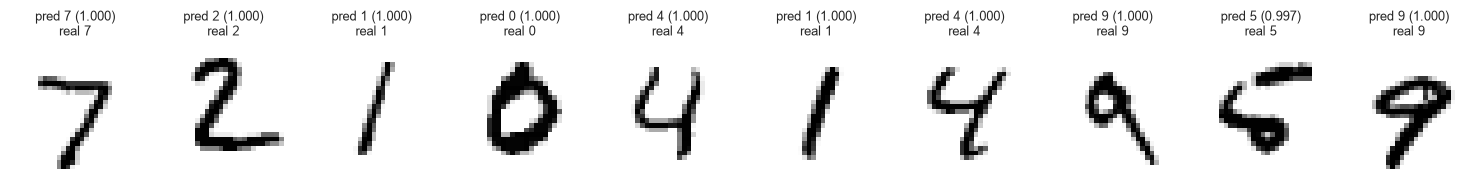

In [12]:
np.set_printoptions(precision=4, suppress=True)
print("q[0] =", q[0])
print("Número predicho para la imagen 0: argmax(q[0]) =", q[0].argmax(), "| etiqueta real:", y_test[0])

pred = q.argmax(axis=1)
fig, axes = plt.subplots(1, 10, figsize=(15, 2.4))
for i, ax in enumerate(axes):
    ax.imshow(X_test[i].reshape(28, 28), cmap="binary")
    ax.set_title(f"pred {pred[i]} ({q[i].max():.3f})\nreal {y_test[i]}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

Test: pérdida = 0.0504, exactitud = 0.9854 (146 errores de 10000)


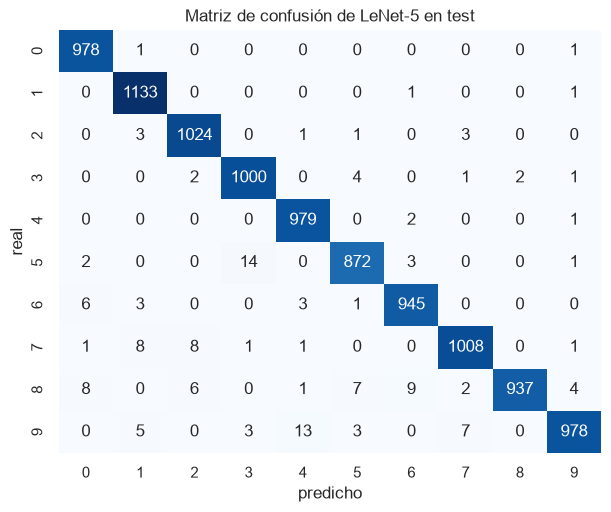

Confusiones más frecuentes (real→predicho):
5→3    14
9→4    13
8→6     9
8→0     8
7→2     8

Confianza media (máx. de q): aciertos = 0.995, errores = 0.782


In [13]:
perdida_test, exactitud_test = model.evaluate(X_test, y_test, verbose=0)
print(f"Test: pérdida = {perdida_test:.4f}, exactitud = {exactitud_test:.4f} "
      f"({np.sum(pred != y_test)} errores de {len(y_test)})")

mc = confusion_matrix(y_test, pred)
plt.figure(figsize=(7, 5.5))
sns.heatmap(mc, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("predicho"); plt.ylabel("real"); plt.title("Matriz de confusión de LeNet-5 en test")
plt.show()

errores = np.where(pred != y_test)[0]
confusiones = pd.Series([f"{y_test[i]}→{pred[i]}" for i in errores]).value_counts()
print("Confusiones más frecuentes (real→predicho):")
print(confusiones.head(5).to_string())
print(f"\nConfianza media (máx. de q): aciertos = {q[pred == y_test].max(axis=1).mean():.3f}, "
      f"errores = {q[errores].max(axis=1).mean():.3f}")

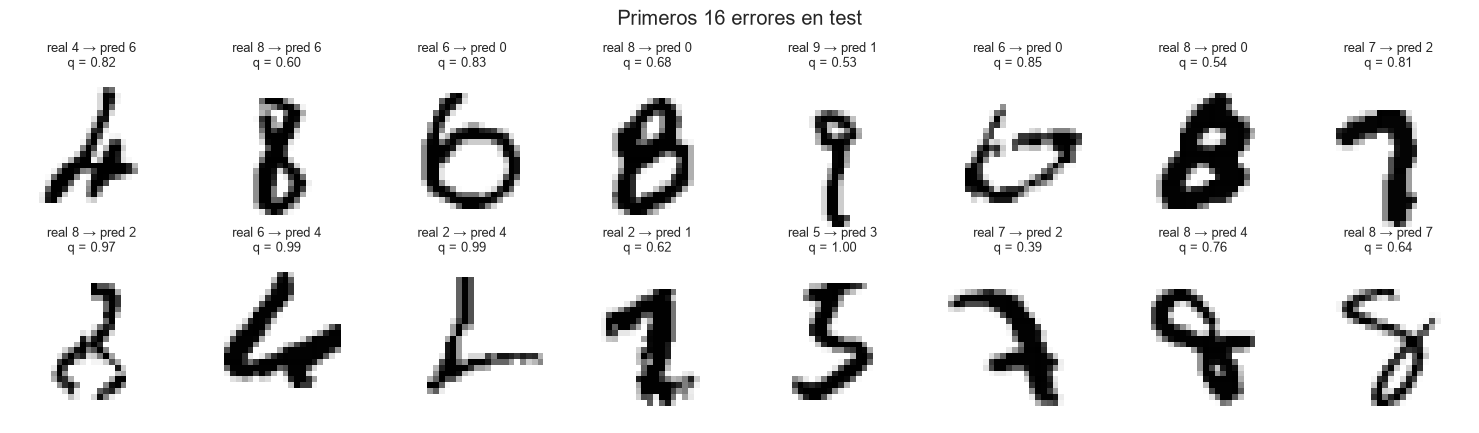

In [14]:
fig, axes = plt.subplots(2, 8, figsize=(15, 4.4))
for ax, i in zip(axes.flat, errores[:16]):
    ax.imshow(X_test[i].reshape(28, 28), cmap="binary")
    ax.set_title(f"real {y_test[i]} → pred {pred[i]}\nq = {q[i].max():.2f}", fontsize=9)
    ax.axis("off")
plt.suptitle("Primeros 16 errores en test")
plt.tight_layout(); plt.show()

**Lectura de `q`.** Cada fila de `q` tiene 10 probabilidades, una por dígito, que suman 1. El número
predicho es la posición de la mayor: `argmax`. Para la primera imagen de test, `q[0]` concentra
prácticamente toda la probabilidad en la posición 7: la red predice 7, que es la etiqueta real. Las
10 primeras imágenes se clasifican bien, todas con probabilidad máxima de 0.997 o más.

**Desempeño en test.** Exactitud de 0.9854 (146 errores de 10 000), con pérdida de 0.0504.

- Las confusiones más frecuentes son 5→3 (14), 9→4 (13), 8→6 (9), 8→0 (8) y 7→2 (8), pares de
  dígitos con trazos parecidos.
- El dígito con más errores es el 8: 937 aciertos de 974, es decir, 37 errores.
- La red es menos segura cuando se equivoca: la probabilidad máxima promedio es 0.995 en los aciertos y
  0.782 en los errores. Aun así, hay errores muy seguros: en la figura, un 5 tomado por 3 con
  $q = 1.00$ y un 6 y un 2 tomados por 4 con $q = 0.99$.
- A simple vista, varios de esos dígitos están escritos de forma atípica o ambigua.

> **Enunciado**
>
> 11. Puede graficar la convergencia del modelo con los siguiente código
> ```python
> import matplotlib.pyplot as plt
> # Graficar la curva de loss
> plt.plot (history.history ['loss'], label='loss')
> plt.plot (history.history ['val_loss'], label='val_loss')
> plt.title ('Curva de loss')
> plt.xlabel ('Época')
> plt.ylabel ('Loss')
> plt.legend ()
> plt.show ()
> # Graficar la curva de accuracy
> plt.plot (history.history ['accuracy'], label='accuracy')
> plt.plot (history.history ['val_accuracy'], label='val_accuracy')
> plt.title ('Curva de accuracy')
> plt.xlabel ('Época')
> plt.ylabel ('Accuracy')
> plt.legend ()
> plt.show ()
> ```

### Punto 11. Convergencia

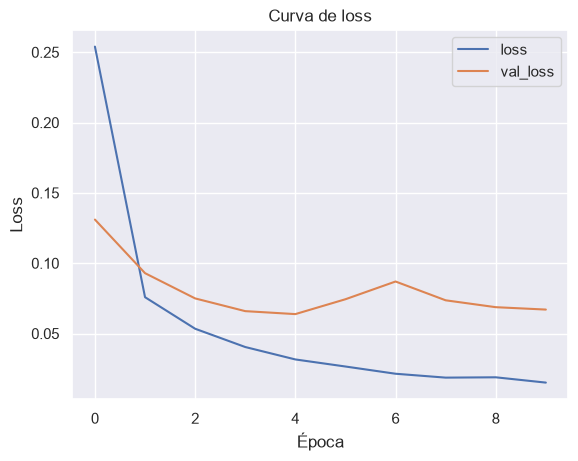

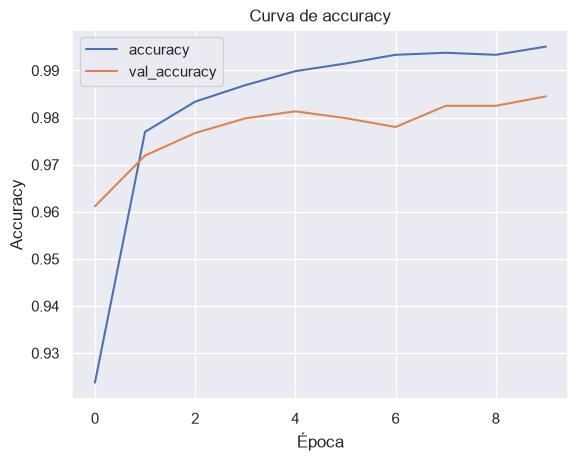

In [15]:
# Código del enunciado
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Curva de loss')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.show()
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.title('Curva de accuracy')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [16]:
h = pd.DataFrame(history.history)
h.index = h.index + 1
h.index.name = "época"
display(h.round(4))

,accuracy,loss,val_accuracy,val_loss
época,,,,
1,0.9237,0.2540,0.9612,0.1310
2,0.9770,0.0758,0.9719,0.0929
3,0.9834,0.0534,0.9767,0.0750
4,0.9869,0.0404,0.9798,0.0659
5,0.9899,0.0316,0.9813,0.0638
6,0.9915,0.0265,0.9799,0.0744
7,0.9933,0.0214,0.9780,0.0870
8,0.9938,0.0186,0.9825,0.0736
9,0.9933,0.0189,0.9825,0.0687


- La pérdida de entrenamiento baja casi todas las épocas, de 0.2540 a 0.0151.
- La pérdida de validación alcanza su mínimo, 0.0638, en la época 5. Después sube hasta 0.0870
  (época 7) y termina en 0.0670.
- La exactitud de validación, en cambio, sigue mejorando un poco y alcanza su máximo, 0.9845, en la
  época 10.

Este desacuerdo entre pérdida y exactitud es típico del inicio del sobreajuste: la red sigue acertando
cada vez más imágenes, pero se vuelve demasiado segura en algunas que falla, y esas pesan mucho en la
entropía cruzada. La brecha entre entrenamiento y validación es pequeña: 0.9951 frente a 0.9845 en
exactitud. Con el `fit` del enunciado, sin parada temprana, el modelo final es el de la época 10. Una
parada temprana sobre `val_loss` habría elegido la época 5.

> **Enunciado**
>
> 12. Una forma alterna de implementar el modelo puede ser dada de la siguiente forma:
> 
> 
> 
> ```python
> from tensorflow.keras.models import Sequential
> from tensorflow.keras.layers import Dense, Dropout, Flatten
> from tensorflow.keras.layers import Conv2D, MaxPooling2D
> from tensorflow.keras.losses import sparse_categorical_crossentropy
> from tensorflow.keras.optimizers import Adam
> 
> X_train = X_train.reshape(60000,28,28,1)
> X_test = X_test.reshape(10000,28,28,1)
> input_shape = (28,28,1)
> model = Sequential()
> model.add(Conv2D(6, kernel_size=(5, 5), activation='relu', input_shape=input_shape))
> model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
> #model.add(Dropout(0.25))
> model.add(Conv2D(16, kernel_size=(5, 5), activation='relu'))
> model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
> #model.add(Dropout(0.25))
> model.add(Flatten())
> model.add(Dense(256, activation='relu'))
> model.add(Dense(84, activation='relu'))
> model.add(Dense(10, activation='softmax'))
> 
> ```

### Punto 12. Implementación alterna

In [17]:
# Código del enunciado (con keras.Input en lugar de input_shape, como recomienda Keras 3)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.losses import sparse_categorical_crossentropy
from tensorflow.keras.optimizers import Adam

X_train = X_train.reshape(60000, 28, 28, 1)
X_test = X_test.reshape(10000, 28, 28, 1)
input_shape = (28, 28, 1)
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model_alt = Sequential()
model_alt.add(keras.Input(shape=input_shape))
model_alt.add(Conv2D(6, kernel_size=(5, 5), activation='relu'))
model_alt.add(MaxPooling2D(pool_size=(2, 2), strides=2))
#model.add(Dropout(0.25))
model_alt.add(Conv2D(16, kernel_size=(5, 5), activation='relu'))
model_alt.add(MaxPooling2D(pool_size=(2, 2), strides=2))
#model.add(Dropout(0.25))
model_alt.add(Flatten())
model_alt.add(Dense(256, activation='relu'))
model_alt.add(Dense(84, activation='relu'))
model_alt.add(Dense(10, activation='softmax'))
model_alt.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        21,588 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,802 (354.70 KB)

 Trainable params: 90,802 (354.70 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model_alt.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
history_alt = model_alt.fit(X_train, y_train, epochs=10, validation_split=0.3, verbose=2)
print(f"Tiempo de entrenamiento: {time.time() - t0:.0f} s")

pred_alt = model_alt.predict(X_test, verbose=0).argmax(axis=1)
comparacion = pd.DataFrame({
    "parámetros": [model.count_params(), model_alt.count_params()],
    "val_accuracy (época 10)": [history.history["val_accuracy"][-1], history_alt.history["val_accuracy"][-1]],
    "mejor val_accuracy": [max(history.history["val_accuracy"]), max(history_alt.history["val_accuracy"])],
    "exactitud test": [np.mean(pred == y_test), np.mean(pred_alt == y_test)],
    "errores test": [np.sum(pred != y_test), np.sum(pred_alt != y_test)],
}, index=["LeNet-5 (punto 5)", "Alterna (punto 12)"])
display(comparacion.round(4))
print("Imágenes de test que fallan ambos modelos:", np.sum((pred != y_test) & (pred_alt != y_test)))

Epoch 1/10


1313/1313 - 10s - 8ms/step - accuracy: 0.9348 - loss: 0.2131 - val_accuracy: 0.9702 - val_loss: 0.1007


Epoch 2/10


1313/1313 - 8s - 6ms/step - accuracy: 0.9798 - loss: 0.0652 - val_accuracy: 0.9756 - val_loss: 0.0811


Epoch 3/10


1313/1313 - 8s - 6ms/step - accuracy: 0.9849 - loss: 0.0485 - val_accuracy: 0.9801 - val_loss: 0.0706


... (13 outputs left out)

1313/1313 - 9s - 7ms/step - accuracy: 0.9949 - loss: 0.0153 - val_accuracy: 0.9860 - val_loss: 0.0597


Tiempo de entrenamiento: 85 s


,parámetros,val_accuracy (época 10),mejor val_accuracy,exactitud test,errores test
LeNet-5 (punto 5),61706,0.9845,0.9845,0.9854,146
Alterna (punto 12),90802,0.9860,0.9860,0.9890,110


Imágenes de test que fallan ambos modelos: 57


In [19]:
# Prueba de McNemar (exacta): solo cuentan las imágenes en que falla exactamente uno de los dos modelos.
# Si ambos fueran igual de buenos, cada una de esas discordancias sería de uno u otro con probabilidad 1/2.
from scipy.stats import binomtest
solo_lenet = int(np.sum((pred != y_test) & (pred_alt == y_test)))
solo_alt = int(np.sum((pred == y_test) & (pred_alt != y_test)))
prueba = binomtest(solo_alt, solo_lenet + solo_alt, 0.5)
print(f"Falla solo LeNet-5: {solo_lenet} | falla solo la alterna: {solo_alt} | p-valor (bilateral) = {prueba.pvalue:.4f}")

Falla solo LeNet-5: 89 | falla solo la alterna: 53 | p-valor (bilateral) = 0.0032


La implementación alterna difiere de LeNet-5 en tres cosas:

- no rellena la imagen (trabaja sobre $28\times28$);
- usa *max pooling* en lugar de promedio;
- su primera capa densa tiene 256 neuronas en lugar de 120.

Por eso tiene 90 802 parámetros frente a 61 706.

| Modelo | Parámetros | `val_accuracy` (época 10) | Exactitud en test | Errores en test |
|---|---|---|---|---|
| LeNet-5 (punto 5) | 61 706 | 0.9845 | 0.9854 | 146 |
| Alterna (punto 12) | 90 802 | 0.9860 | **0.9890** | **110** |

- La alterna comete 36 errores menos. 57 imágenes las fallan ambos modelos; de las discordantes, 89
  las falla solo LeNet-5 y 53 solo la alterna.
- La prueba de McNemar da p = 0.0032, así que la diferencia no se explica por el azar del conjunto
  de test.
- Dos matices. Cada red se entrenó una sola vez, con una semilla, de modo que parte de la diferencia
  puede deberse a la inicialización. Y como la alterna cambia tres cosas a la vez, este experimento no
  permite saber cuál de ellas produce la mejora.

## Parte 2. CIFAR-100 con BatchNormalization y Dropout

> **Enunciado**
>
> 13. Emplea la arquitectura anterior para el  
>   el dataset cifar100,  empleando BatchNormalization y dropout.
> 
> 
> - BatchNormalization es una técnica que se usa para acelerar y estabilizar el entrenamiento de las redes neuronales artificiales, mediante la normalización de las entradas de cada capa, re-centrando y re-escalando los datos.
> 
>   BatchNormalization se aplica justo antes de la función de activación de cada capa, y consiste en centrar y normalizar cada mini-lote con una media y una desviación estándar calculadas con los datos del mini-lote, y luego re-escalar y desplazar los datos de nuevo con parámetros aprendidos por la red durante el entrenamiento. Estos parámetros permiten que la red se adapte a la distribución óptima de las activaciones para cada capa. Además, al introducir cierto ruido en los datos, BatchNormalization actúa como una regularización y ayuda a reducir el sobreajuste.
> 
> 
> - El dropout es una técnica de regularización para reducir el sobreajuste en redes neuronales artificiales. El sobreajuste ocurre cuando el modelo se ajusta demasiado a los datos de entrenamiento y pierde capacidad de generalizar a nuevos datos. El dropout consiste en eliminar aleatoriamente algunas neuronas de la red durante el entrenamiento, lo que hace que el modelo sea más robusto y menos dependiente de ciertas conexiones. El dropout se puede interpretar como una forma de promediar varios modelos más pequeños y diferentes, lo que mejora el rendimiento final.
> 
>   El dropout se aplica a cada capa de la red, especificando una probabilidad de mantener cada neurona activa. Por ejemplo, si se usa un dropout de 0.2, significa que el 20% de las neuronas se desactivarán en cada iteración del entrenamiento. El dropout solo se usa durante el entrenamiento, no durante la inferencia o la evaluación. El dropout se puede combinar con otras técnicas de regularización, como la normalización de pesos o la normalización por lotes.
> 
> 
> 
> 
> ```python
> import numpy as np
> import pandas as pd
> import matplotlib.pyplot as plt
> import seaborn as sns; sns.set()
> from tensorflow import keras
> 
> 
> (train_image, train_label) , (test_image, test_label) = keras.datasets.cifar100.load_data()
> 
> 
> plt.imshow(train_image[30])
> plt.axis('off')
> ```
> 
> intenta agregar, lineas como las siguientes en los lugares mas estrategicos:
> 
> 
> ```python
> keras.layers.Dropout(0.2),
> keras.layers.BatchNormalization()
> ```

### Punto 13. Arquitectura del punto 12 en CIFAR-100

train: (50000, 32, 32, 3) uint8 | test: (10000, 32, 32, 3) | etiquetas: (50000, 1)
Clases: 100 | imágenes por clase en train: [500] | en test: [100]
Primeras clases: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle']


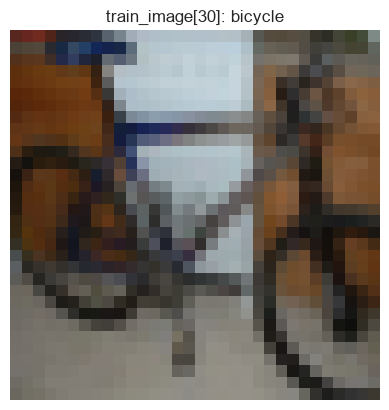

In [20]:
(train_image, train_label), (test_image, test_label) = keras.datasets.cifar100.load_data()
print("train:", train_image.shape, train_image.dtype, "| test:", test_image.shape, "| etiquetas:", train_label.shape)
print("Clases:", len(np.unique(train_label)), "| imágenes por clase en train:", np.unique(np.bincount(train_label.ravel())),
      "| en test:", np.unique(np.bincount(test_label.ravel())))

# Nombres de las 100 clases: archivo 'meta' del conjunto original, que Keras deja en su caché
import glob, pickle
# (la subcarpeta exacta cambia entre versiones de Keras, por eso se busca)
ruta_meta = glob.glob(os.path.join(os.path.expanduser("~"), ".keras", "datasets", "**", "cifar-100-python", "meta"),
                      recursive=True)[0]
with open(ruta_meta, "rb") as f:
    nombres = pickle.load(f, encoding="latin1")["fine_label_names"]
print("Primeras clases:", nombres[:8])

plt.imshow(train_image[30])
plt.axis('off')
plt.title(f"train_image[30]: {nombres[train_label[30, 0]]}")
plt.show()

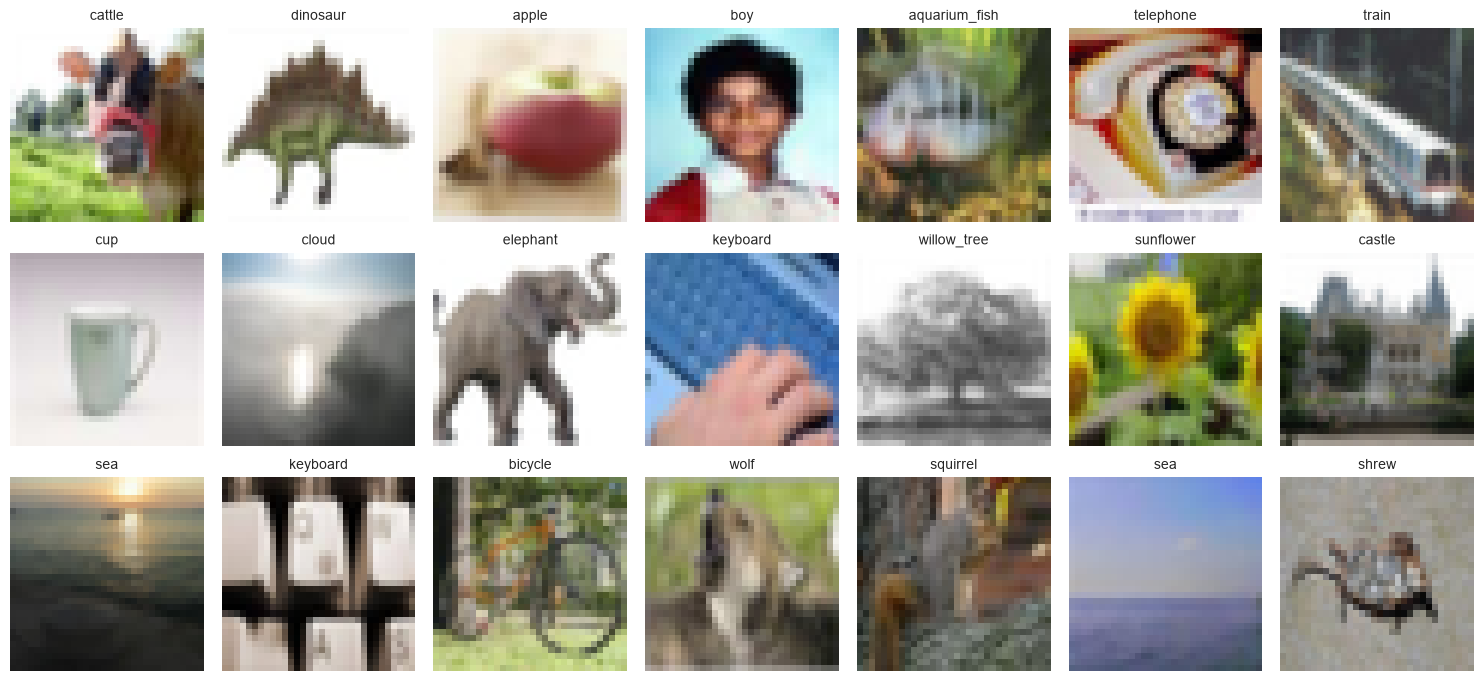

In [21]:
fig, axes = plt.subplots(3, 7, figsize=(15, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_image[i])
    ax.set_title(nombres[train_label[i, 0]], fontsize=10)
    ax.axis('off')
plt.tight_layout(); plt.show()

train_image = train_image / 255.0
test_image = test_image / 255.0

**Arquitectura.** Se toma la red del punto 12 (Conv 6 → MaxPool → Conv 16 → MaxPool → Dense 256 →
Dense 84) con dos cambios obligados por los datos: la entrada pasa a ser de $32\times32\times3$ y la
salida a 100 clases. Con la entrada de $32\times32$, el bloque convolucional entrega
$5\times5\times16 = 400$ valores, igual que LeNet-5.

**Dónde van BatchNormalization y Dropout.**

- **BatchNormalization después de cada capa convolucional o densa y antes de su activación**, como
  describe el enunciado ("se aplica justo antes de la función de activación"). Por eso las capas con BN
  no llevan `activation` y van seguidas de `Activation("relu")`. Una capa con BN no necesita sesgo
  propio, pero se deja por simplicidad.
- **Dropout(0.2) después de las dos capas densas ocultas.** Ahí se concentran los parámetros (la capa
  de 256 neuronas tiene más de 100 000 de los poco más de 130 000 de la red) y, por tanto, el mayor
  riesgo de sobreajuste. En las capas convolucionales, con pocos filtros (6 y 16), apagar activaciones
  le quitaría a la red la poca capacidad que tiene para extraer rasgos.

Para medir el efecto de las dos técnicas, después del punto 15 se entrena la misma red sin ellas.

In [22]:
def red_cifar(regularizada):
    """Arquitectura del punto 12 para 32x32x3 y 100 clases. Si regularizada=True se añaden
    BatchNormalization (antes de cada activación) y Dropout (en la parte densa)."""
    def bloque(tipo, **kw):
        if regularizada:      # capa lineal -> BatchNormalization -> activación
            return [tipo(**kw), keras.layers.BatchNormalization(), keras.layers.Activation("relu")]
        return [tipo(activation="relu", **kw)]

    capas = [keras.Input(shape=(32, 32, 3))]
    capas += bloque(keras.layers.Conv2D, filters=6, kernel_size=5)
    capas += [keras.layers.MaxPooling2D(pool_size=2, strides=2)]
    capas += bloque(keras.layers.Conv2D, filters=16, kernel_size=5)
    capas += [keras.layers.MaxPooling2D(pool_size=2, strides=2), keras.layers.Flatten()]
    capas += bloque(keras.layers.Dense, units=256)
    capas += [keras.layers.Dropout(0.2)] if regularizada else []
    capas += bloque(keras.layers.Dense, units=84)
    capas += [keras.layers.Dropout(0.2)] if regularizada else []
    capas += [keras.layers.Dense(100, activation="softmax")]
    return keras.models.Sequential(capas, name="cifar_bn_dropout" if regularizada else "cifar_sin_regularizar")


keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model_cifar = red_cifar(regularizada=True)
model_cifar.summary()

Model: "cifar_bn_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 6)      │            24 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 10, 10, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 10, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       102,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        21,588 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 84)             │           336 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │         8,500 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 137,064 (535.41 KB)

 Trainable params: 136,340 (532.58 KB)

 Non-trainable params: 724 (2.83 KB)

> **Enunciado**
>
> 14. Emplea el siguiente compilador:
> 
> El optimizador de NAdam (Nesterov-accelerated Adaptive Moment Estimation) es una variante de Adam que incorpora el método de Nesterov, que consiste en utilizar una predicción de la posición futura de los parámetros para calcular el gradiente, en lugar de la posición actual. Esto hace que el algoritmo sea más sensible a los cambios de dirección del gradiente y evite oscilaciones innecesarias. NAdam también modifica la forma de calcular el momento y la magnitud del gradiente, usando una media móvil exponencial sesgada hacia cero en lugar de una media móvil exponencial simple.
> 
> 
> ```python
> model.compile(optimizer='nadam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
> ```
> 
> El número de épocas que se necesita para entrenar una red neuronal depende de varios factores, como el tamaño de los datos, la complejidad del modelo, la función de pérdida, el algoritmo de optimización, la tasa de aprendizaje, etc. No hay una regla fija para elegir el número de épocas, pero se puede usar el criterio de parada temprana, que consiste en monitorear el error de validación y detener el entrenamiento cuando este empiece a aumentar, lo que indica un sobreajuste del modelo.

### Punto 14. Compilación con NAdam

In [23]:
model_cifar.compile(optimizer='nadam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

> **Enunciado**
>
> 15. Emplea early_stooping y realiza el fit
> 
> 
> 
> ```python
> early_stopping = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
> ```
> 
> El parámetro patience=5 indica el número de épocas sin mejora después de las cuales se detendrá el entrenamiento. El parámetro restore_best_weights=True indica que se restaurarán los pesos del modelo desde la época con el mejor valor de la métrica monitoreada. Esto puede ayudar a evitar el sobreajuste y mejorar el rendimiento del modelo
> 
> 
> 
> ```python
> history = model.fit(train_image, train_label, epochs=30, validation_split=0.2 , batch_size=64, callbacks=[early_stopping])
> ```

### Punto 15. Parada temprana y entrenamiento

In [24]:
early_stopping = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
t0 = time.time()
history_cifar = model_cifar.fit(train_image, train_label, epochs=30, validation_split=0.2, batch_size=64,
                                callbacks=[early_stopping], verbose=2)
print(f"Tiempo: {time.time() - t0:.0f} s | épocas: {len(history_cifar.history['loss'])} | "
      f"época restaurada: {early_stopping.best_epoch + 1}")

Epoch 1/30


625/625 - 13s - 20ms/step - accuracy: 0.0980 - loss: 4.0124 - val_accuracy: 0.1362 - val_loss: 3.7135


Epoch 2/30


625/625 - 8s - 12ms/step - accuracy: 0.1772 - loss: 3.4636 - val_accuracy: 0.2047 - val_loss: 3.3027


Epoch 3/30


625/625 - 7s - 12ms/step - accuracy: 0.2182 - loss: 3.2277 - val_accuracy: 0.2404 - val_loss: 3.1108


... (23 outputs left out)

625/625 - 8s - 12ms/step - accuracy: 0.3730 - loss: 2.3947 - val_accuracy: 0.3029 - val_loss: 2.8475


Epoch 16/30


625/625 - 8s - 12ms/step - accuracy: 0.3775 - loss: 2.3564 - val_accuracy: 0.3146 - val_loss: 2.7872


Tiempo: 127 s | épocas: 16 | época restaurada: 11


#### Comparación: la misma red sin BatchNormalization ni Dropout

Para saber qué aportan las dos técnicas se entrena la misma arquitectura sin ellas, con el mismo
compilador, la misma parada temprana, la misma partición de validación y la misma semilla.

In [25]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model_base = red_cifar(regularizada=False)
model_base.compile(optimizer='nadam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
parada_base = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
t0 = time.time()
history_base = model_base.fit(train_image, train_label, epochs=30, validation_split=0.2, batch_size=64,
                              callbacks=[parada_base], verbose=2)
print(f"Tiempo: {time.time() - t0:.0f} s | épocas: {len(history_base.history['loss'])} | "
      f"época restaurada: {parada_base.best_epoch + 1}")

Epoch 1/30


625/625 - 8s - 13ms/step - accuracy: 0.0728 - loss: 4.0936 - val_accuracy: 0.1187 - val_loss: 3.8115


Epoch 2/30


625/625 - 5s - 8ms/step - accuracy: 0.1517 - loss: 3.5986 - val_accuracy: 0.1716 - val_loss: 3.5030


Epoch 3/30


625/625 - 5s - 8ms/step - accuracy: 0.2015 - loss: 3.3250 - val_accuracy: 0.2026 - val_loss: 3.3349


... (17 outputs left out)

625/625 - 5s - 8ms/step - accuracy: 0.3738 - loss: 2.4313 - val_accuracy: 0.2606 - val_loss: 3.1559


Epoch 13/30


625/625 - 5s - 8ms/step - accuracy: 0.3868 - loss: 2.3698 - val_accuracy: 0.2623 - val_loss: 3.1833


Tiempo: 67 s | épocas: 13 | época restaurada: 8


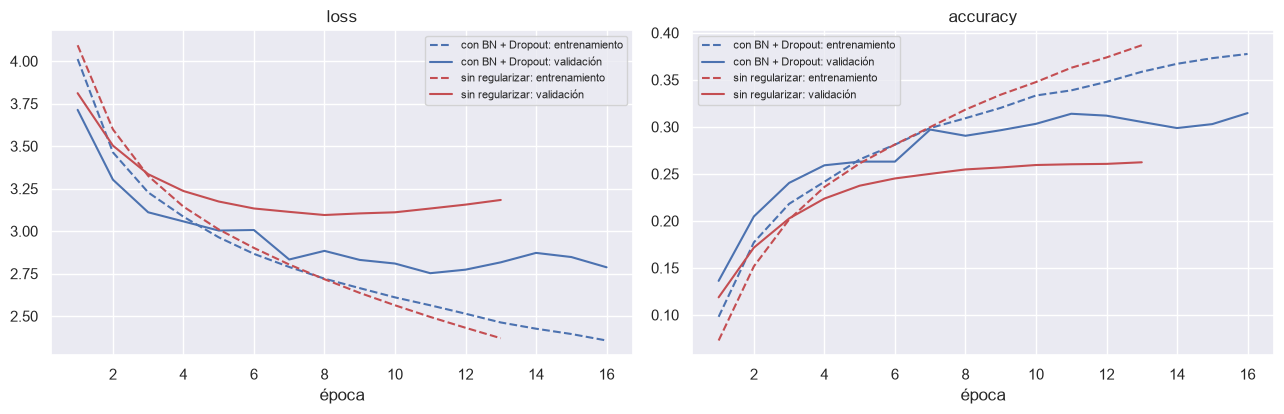

,parámetros,épocas,época restaurada,train acc,val acc,val loss,test acc (top-1),test acc (top-5)
modelo,,,,,,,,
con BN + Dropout,137064,16,11,0.3388,0.3139,2.7524,0.3119,0.6066
sin regularizar,135616,13,8,0.3183,0.2547,3.0947,0.2623,0.5485


Exactitud de adivinar al azar (100 clases equilibradas): 0.01 top-1, 0.05 top-5


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for hist, etiqueta, color in [(history_cifar.history, "con BN + Dropout", "C0"), (history_base.history, "sin regularizar", "C3")]:
    for ax, clave in zip(axes, ["loss", "accuracy"]):
        ax.plot(range(1, len(hist[clave]) + 1), hist[clave], color=color, ls="--", label=f"{etiqueta}: entrenamiento")
        ax.plot(range(1, len(hist[clave]) + 1), hist["val_" + clave], color=color, label=f"{etiqueta}: validación")
for ax, clave in zip(axes, ["loss", "accuracy"]):
    ax.set(xlabel="época", title=clave); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

def top_k(prob, y, k):
    return np.mean([y_i in fila for y_i, fila in zip(y, np.argsort(prob, axis=1)[:, -k:])])

filas = []
for nombre, m, hist, cb in [("con BN + Dropout", model_cifar, history_cifar.history, early_stopping),
                            ("sin regularizar", model_base, history_base.history, parada_base)]:
    prob = m.predict(test_image, verbose=0)
    b = cb.best_epoch
    filas.append({"modelo": nombre, "parámetros": m.count_params(), "épocas": len(hist["loss"]),
                  "época restaurada": b + 1, "train acc": hist["accuracy"][b], "val acc": hist["val_accuracy"][b],
                  "val loss": hist["val_loss"][b], "test acc (top-1)": np.mean(prob.argmax(1) == test_label.ravel()),
                  "test acc (top-5)": top_k(prob, test_label.ravel(), 5)})
    if nombre == "con BN + Dropout":
        prob_cifar = prob
display(pd.DataFrame(filas).set_index("modelo").round(4))
print("Exactitud de adivinar al azar (100 clases equilibradas): 0.01 top-1, 0.05 top-5")

Mejores clases:
oak_tree    0.79
road        0.76
sea         0.75
wardrobe    0.75
apple       0.69

Peores clases:
otter     0.01
beaver    0.03
possum    0.03
snake     0.04
lizard    0.06


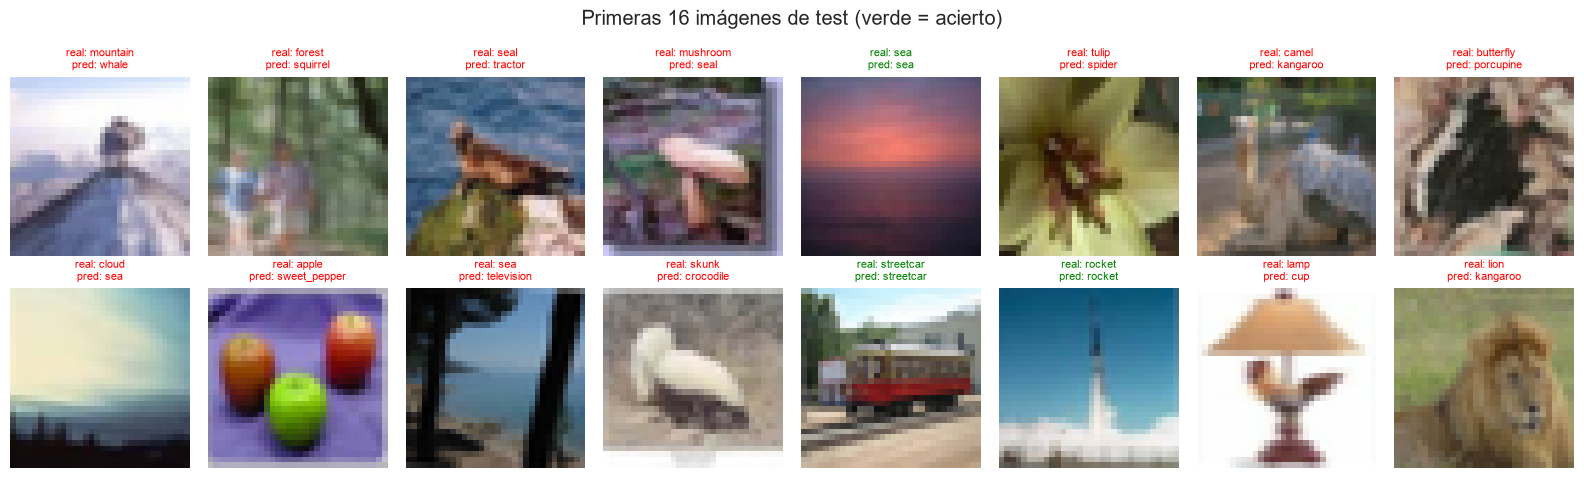

In [27]:
# Exactitud por clase del modelo regularizado: las 5 mejores y las 5 peores
pred_cifar = prob_cifar.argmax(1)
acc_clase = pd.Series([np.mean(pred_cifar[test_label.ravel() == c] == c) for c in range(100)], index=nombres)
print("Mejores clases:\n" + acc_clase.nlargest(5).round(2).to_string())
print("\nPeores clases:\n" + acc_clase.nsmallest(5).round(2).to_string())

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(test_image[i])
    real, p = test_label[i, 0], pred_cifar[i]
    ax.set_title(f"real: {nombres[real]}\npred: {nombres[p]}", fontsize=8, color="green" if real == p else "red")
    ax.axis("off")
plt.suptitle("Primeras 16 imágenes de test (verde = acierto)")
plt.tight_layout(); plt.show()

**Resultados en CIFAR-100** (10 000 imágenes de test; al azar se acertaría el 1 % en top-1 y el 5 % en
top-5):

| Modelo | Parámetros | Épocas | Época restaurada | Exactitud val | Exactitud test (top-1) | Exactitud test (top-5) |
|---|---|---|---|---|---|---|
| **Con BN + Dropout** | 137 064 | 16 | 11 | 0.3139 | **0.3119** | **0.6066** |
| Sin regularizar | 135 616 | 13 | 8 | 0.2547 | 0.2623 | 0.5485 |

- **BatchNormalization y Dropout mejoran la generalización.** Con la misma arquitectura, la exactitud
  de test sube 5 puntos en top-1 (de 0.262 a 0.312) y 6 en top-5. Con 10 000 imágenes de test, el
  error estándar de cada exactitud es de unos 0.5 puntos, así que la diferencia es grande frente al
  ruido del test, aunque proviene de un solo entrenamiento por modelo.
- **Las curvas muestran por qué.** Sin regularizar, la exactitud de entrenamiento sube sin parar (0.3868
  en la época 13), pero la de validación se estanca cerca de 0.26. Su pérdida de validación toca el
  mínimo en la época 8 y luego sube: sobreajuste, con una brecha de unos 12 puntos al final. Con BN y
  Dropout, la validación sigue mejorando hasta la época 11 y queda a solo 2.5 puntos del entrenamiento
  en la época restaurada (0.3139 frente a 0.3388). En las primeras épocas la validación incluso supera
  al entrenamiento. Pasa también sin regularizar (en la época 1, 0.119 de validación frente a 0.073 de
  entrenamiento), así que en parte se debe a que la exactitud de entrenamiento es el promedio de toda la
  época, con la red todavía mejorando; en el modelo con Dropout, además, se mide con neuronas apagadas.
- **Costo.** Las capas de BatchNormalization añaden 1 448 parámetros: 724 entrenables y 724 no
  entrenables, que son las medias y varianzas acumuladas. Cada época tarda más, y la curva de
  validación es más ruidosa.
- **Nivel absoluto.** Una exactitud de 31 % en top-1 es modesta: la red tiene solo 6 y 16 filtros
  convolucionales para distinguir 100 clases. Como referencia, el notebook de la sesión 17
  (`Sesion_17_convolution_nn2.ipynb`) entrena una red más profunda (unos 564 000 parámetros) y deja
  guardada una exactitud en test de 0.4894 (cifra copiada de la salida de ese notebook, no reproducida
  aquí). Parece que esta arquitectura de LeNet se queda corta de capacidad para el problema.
- **Por clase.** El modelo regularizado acierta mejor *oak_tree* (0.79), *road* (0.76), *sea* y
  *wardrobe* (0.75) y *apple* (0.69). Acierta peor *otter* (0.01), *beaver* y *possum* (0.03), *snake*
  (0.04) y *lizard* (0.06). Mi interpretación, que no comprobé aparte, es que las mejores tienen colores o
  fondos característicos y que las peores son animales de tonos parecidos, difíciles de separar con
  imágenes de $32\times32$. En las 16 primeras
  imágenes de test acierta 3 (*sea*, *streetcar* y *rocket*).

## Parte 3. VGG16 preentrenada

> **Enunciado**
>
> Ahora vamos a implementar una red VGG16, para ello puedes emplear la siguiente linea de código:
> 
> 
> ```python
> from tensorflow import keras
> import matplotlib.pyplot as plt
> import matplotlib.image as mpimg
> import numpy as np
> 
> # Indian elephant
> !wget https://upload.wikimedia.org/wikipedia/commons/f/f9/Zoorashia_elephant.jpg -O indian_elephant.jpg
> # African elephant
> !wget https://upload.wikimedia.org/wikipedia/commons/b/bf/African_Elephant_%28Loxodonta_africana%29_male_%2817289351322%29.jpg -O african_elephant.jpg
> #!wget https://github.com/ssanchezgoe/diplomado_udea/blob/master/image/african_elephant_bull.jpg?raw=true -O african_elephant.jpg
> 
> # Choose the elephant to be classified
> img_path = 'african_elephant.jpg'
> 
> img = mpimg.imread(img_path)
> implot = plt.imshow(img)
> 
> print("Tamaño de la imagen:",img.shape)
> ```
> 
> 
> ```python
> from keras.preprocessing import image
> 
> model = keras.applications.vgg16.VGG16(weights='imagenet', include_top=True)
> model.summary()
> 
> ```
> 
> 
> ```python
> img = image.load_img(img_path, target_size=(224, 224))
> x = image.img_to_array(img)
> x = np.expand_dims(x, axis=0)# Añadir una dimensión extra para el lote
> x = keras.applications.vgg16.preprocess_input(x)
> 
> features = model.predict(x)
> 
> print("Prediction", keras.applications.vgg16.decode_predictions(features, top=3)[0])
> ```

### Clasificación de elefantes con VGG16

**VGG16** es una red convolucional profunda con 16 capas con pesos (13 convolucionales y 3 densas, como
se comprueba abajo). Se carga con los pesos entrenados en ImageNet, un conjunto de 1 000 clases que
incluye varias de elefantes. No se entrena nada: solo se usa para clasificar dos fotos de Wikimedia, un
elefante asiático (*indian*) y uno africano.

Tamaño de la imagen indian_elephant.jpg : (600, 800, 3)


Tamaño de la imagen african_elephant.jpg : (4000, 3648, 3)


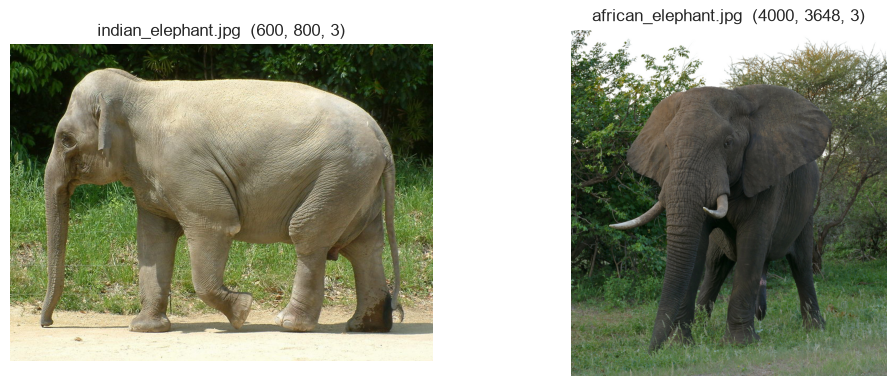

In [28]:
import tempfile
import urllib.request
import matplotlib.image as mpimg
from keras.preprocessing import image

# El enunciado usa !wget (solo en Colab). Aquí se descarga con urllib a una carpeta temporal, para no
# dejar imágenes en la carpeta de entrega. Wikimedia exige identificar el cliente (User-Agent).
carpeta = tempfile.mkdtemp()
urls = {
    "indian_elephant.jpg": "https://upload.wikimedia.org/wikipedia/commons/f/f9/Zoorashia_elephant.jpg",
    "african_elephant.jpg": "https://upload.wikimedia.org/wikipedia/commons/b/bf/African_Elephant_%28Loxodonta_africana%29_male_%2817289351322%29.jpg",
}
rutas = {}
for nombre_img, url in urls.items():
    pedido = urllib.request.Request(url, headers={"User-Agent": "Laboratorio-AprendizajeEstadistico-UdeA/1.0 (uso academico)"})
    rutas[nombre_img] = os.path.join(carpeta, nombre_img)
    with urllib.request.urlopen(pedido) as r, open(rutas[nombre_img], "wb") as f:
        f.write(r.read())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (nombre_img, ruta) in zip(axes, rutas.items()):
    img = mpimg.imread(ruta)
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{nombre_img}  {img.shape}")
    print("Tamaño de la imagen", nombre_img, ":", img.shape)
plt.show()

In [29]:
model_vgg = keras.applications.vgg16.VGG16(weights='imagenet', include_top=True)
model_vgg.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:
for nombre_img, img_path in rutas.items():
    img = image.load_img(img_path, target_size=(224, 224))
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)          # Añadir una dimensión extra para el lote
    x = keras.applications.vgg16.preprocess_input(x)
    features = model_vgg.predict(x, verbose=0)
    print(nombre_img, "->", [(clase, round(float(p), 4)) for _, clase, p in
                              keras.applications.vgg16.decode_predictions(features, top=3)[0]])

indian_elephant.jpg -> [('Indian_elephant', 0.7194), ('African_elephant', 0.2414), ('tusker', 0.0363)]


african_elephant.jpg -> [('African_elephant', 0.9014), ('tusker', 0.0897), ('Indian_elephant', 0.0089)]


In [31]:
# ¿Qué hace preprocess_input? Se compara con el preprocesado 'caffe': RGB -> BGR y resta de la media de ImageNet
x_prueba = np.random.default_rng(0).uniform(0, 255, size=(1, 4, 4, 3)).astype("float32")
manual = x_prueba[..., ::-1] - np.array([103.939, 116.779, 123.68], dtype="float32")
print("preprocess_input == BGR - media:", np.allclose(keras.applications.vgg16.preprocess_input(x_prueba.copy()), manual))
print("Capas con pesos de VGG16:", sum(len(c.get_weights()) > 0 for c in model_vgg.layers),
      "| Conv2D:", sum(isinstance(c, keras.layers.Conv2D) for c in model_vgg.layers),
      "| Dense:", sum(isinstance(c, keras.layers.Dense) for c in model_vgg.layers),
      "| clases de salida:", model_vgg.output_shape[-1])
densos = sum(c.count_params() for c in model_vgg.layers if isinstance(c, keras.layers.Dense))
print(f"Parámetros en las capas densas: {densos:,} de {model_vgg.count_params():,} "
      f"({densos / model_vgg.count_params():.1%})")
print(f"VGG16 tiene {model_vgg.count_params() / model.count_params():,.0f} veces los parámetros de LeNet-5")

preprocess_input == BGR - media: True
Capas con pesos de VGG16: 16 | Conv2D: 13 | Dense: 3 | clases de salida: 1000
Parámetros en las capas densas: 123,642,856 de 138,357,544 (89.4%)
VGG16 tiene 2,242 veces los parámetros de LeNet-5


**Resultados (top-3).**

| Imagen | 1.ª | 2.ª | 3.ª |
|---|---|---|---|
| `indian_elephant.jpg` | **Indian_elephant** (0.7194) | African_elephant (0.2414) | tusker (0.0363) |
| `african_elephant.jpg` | **African_elephant** (0.9014) | tusker (0.0897) | Indian_elephant (0.0089) |

- **Las dos imágenes se clasifican correctamente.** Las tres opciones de cada una son clases relacionadas
  con elefantes: asiático, africano y *tusker* (animal con colmillos prominentes).
- La red está más segura con el africano (0.90) que con el asiático (0.72), y en el africano la segunda
  opción es *tusker*, coherente con los colmillos visibles en la foto.
- **Preprocesado.** `load_img(target_size=(224, 224))` lleva cada imagen (600×800 y 4000×3648 píxeles) al
  tamaño de entrada de VGG16. `preprocess_input` invierte los canales a BGR y resta la media de ImageNet;
  la celda lo comprueba numéricamente. Es el mismo preprocesado con que se entrenó la red, por eso es
  obligatorio.
- **Escala.** VGG16 tiene 138 357 544 parámetros, unas 2 240 veces los de LeNet-5, y el 89.4 % está
  en sus 3 capas densas (la última celda de código lo calcula).

## Conclusiones

1. **LeNet-5 en MNIST.** Implementada según la figura (61 706 parámetros, 78 % de ellos en la primera
   capa densa), alcanza 98.54 % de exactitud en test en 10 épocas. Sus errores se concentran en pares
   de dígitos parecidos (5→3, 9→4) y la red es menos segura cuando falla. La pérdida de validación toca
   su mínimo en la época 5, primera señal de sobreajuste.
2. **Implementación alterna.** Con *max pooling* y una capa densa de 256 neuronas, obtiene 98.90 %
   (36 errores menos, McNemar $p = 0.0032$). Con una sola semilla y tres cambios simultáneos, no se
   puede atribuir la mejora a uno en particular.
3. **CIFAR-100.** La misma arquitectura, con **BatchNormalization antes de cada activación y Dropout en
   la parte densa, sube la exactitud de test de 26.2 % a 31.2 %** (top-5: de 54.9 % a 60.7 %) y
   reduce la brecha entre entrenamiento y validación. Aun así, una red tan pequeña tiene poca capacidad
   para 100 clases.
4. **VGG16 preentrenada.** Clasifica correctamente los dos elefantes (asiático 0.72, africano 0.90) sin
   ningún entrenamiento propio, lo que muestra el valor de reutilizar una red grande entrenada en
   ImageNet.

#### Reproducibilidad

In [32]:
import sys, sklearn
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| TensorFlow", tf.__version__,
      "| Keras", keras.__version__)

Python 3.14.7 | numpy 2.5.3 | TensorFlow 2.22.0-rc0 | Keras 3.15.1


Todas las semillas están fijas (`SEED = 42` y `keras.utils.set_random_seed` antes de cada modelo) y
TensorFlow trabaja en modo determinista (`enable_op_determinism`). Una nueva ejecución reproduce las
mismas cifras; solo cambian los tiempos impresos. En CPU el notebook completo tarda unos 10 minutos en este equipo.
Necesita descargar MNIST (11 MB), CIFAR-100 (169 MB), los pesos de VGG16 (528 MB) y las dos imágenes de
Wikimedia. Keras guarda los tres primeros en su caché (`~/.keras`) y las imágenes se guardan en una
carpeta temporal.